In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import warnings
warnings.simplefilter("ignore")
%matplotlib inline

sns.set(style="darkgrid")

Изучим датасет

In [2]:
data = pd.read_csv("winequality-red.csv", sep=';')
print(data.shape)

(1599, 12)


In [3]:
display(data.head())

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [4]:
display(data.describe())

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [5]:
print(f'nulls:{data.isna().sum()}')
print(f'duplicates:{data.duplicated().sum()}')

nulls:fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64
duplicates:240


В датасете есть 240 полных дубликатов, во избежание утечек данных из train в test, очистим датасет от повторяющихся строк

In [6]:
data = data.drop_duplicates().reset_index(drop=True)
print(data.shape)

(1359, 12)


Разделим датасет на тренировачные и тестовые данные, построим гистограмму для целевой переменной. Значение test_size было выбрано как 0.2, т.к. размер исходного датасета мал и при больших значениях этого показателя моделям может недоставать данных для обучения и метрики окажутся хуже.

<Axes: xlabel='quality', ylabel='Density'>

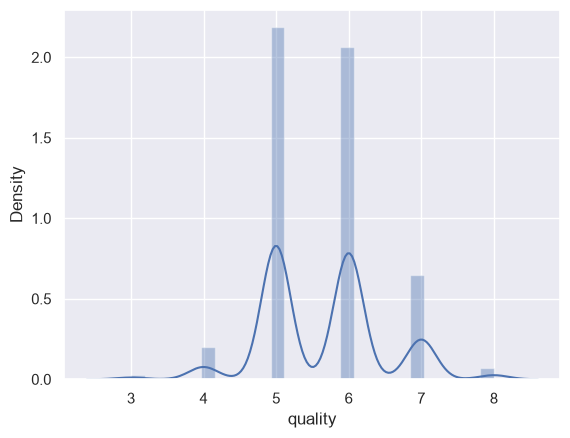

In [7]:
from sklearn.model_selection import train_test_split

X = data.drop(columns=["quality"])
y = data["quality"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size = 0.2,
    random_state = 42,
)
sns.distplot(y_train)

Выбросов в данных не наблюдается. Можно заметить, что строк с quality = 3, 4, 8, 9 очень мало, так что модели вряд ли смогут обучиться отличать такие данные и будут иметь наибольшую ошибку на них. Теперь построим диаграмму корреляций между признаками и целевой переменной.

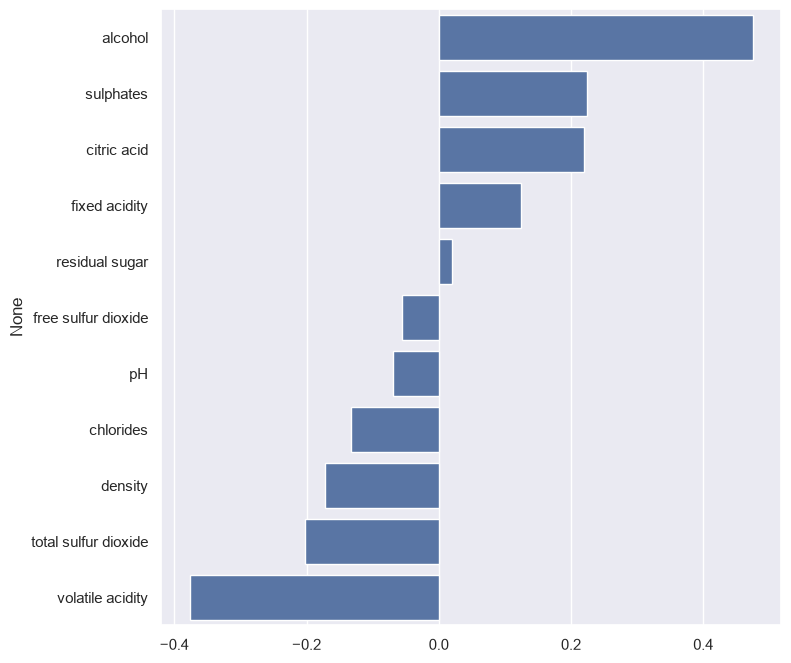

In [8]:
correlations = X_train.corrwith(y_train).sort_values(ascending=False)

plot = sns.barplot(y=correlations.index, x=correlations.values)
plot.figure.set_size_inches(8, 8)

Посмотрим на топ-3 признака по модулю значения внимательнее ("alcohol", "volatile acidity", "sulphates"), нарисовав график зависимости целевой переменной от каждого из выделенных признаков (scatter plot) и гистограмму для каждого признака.

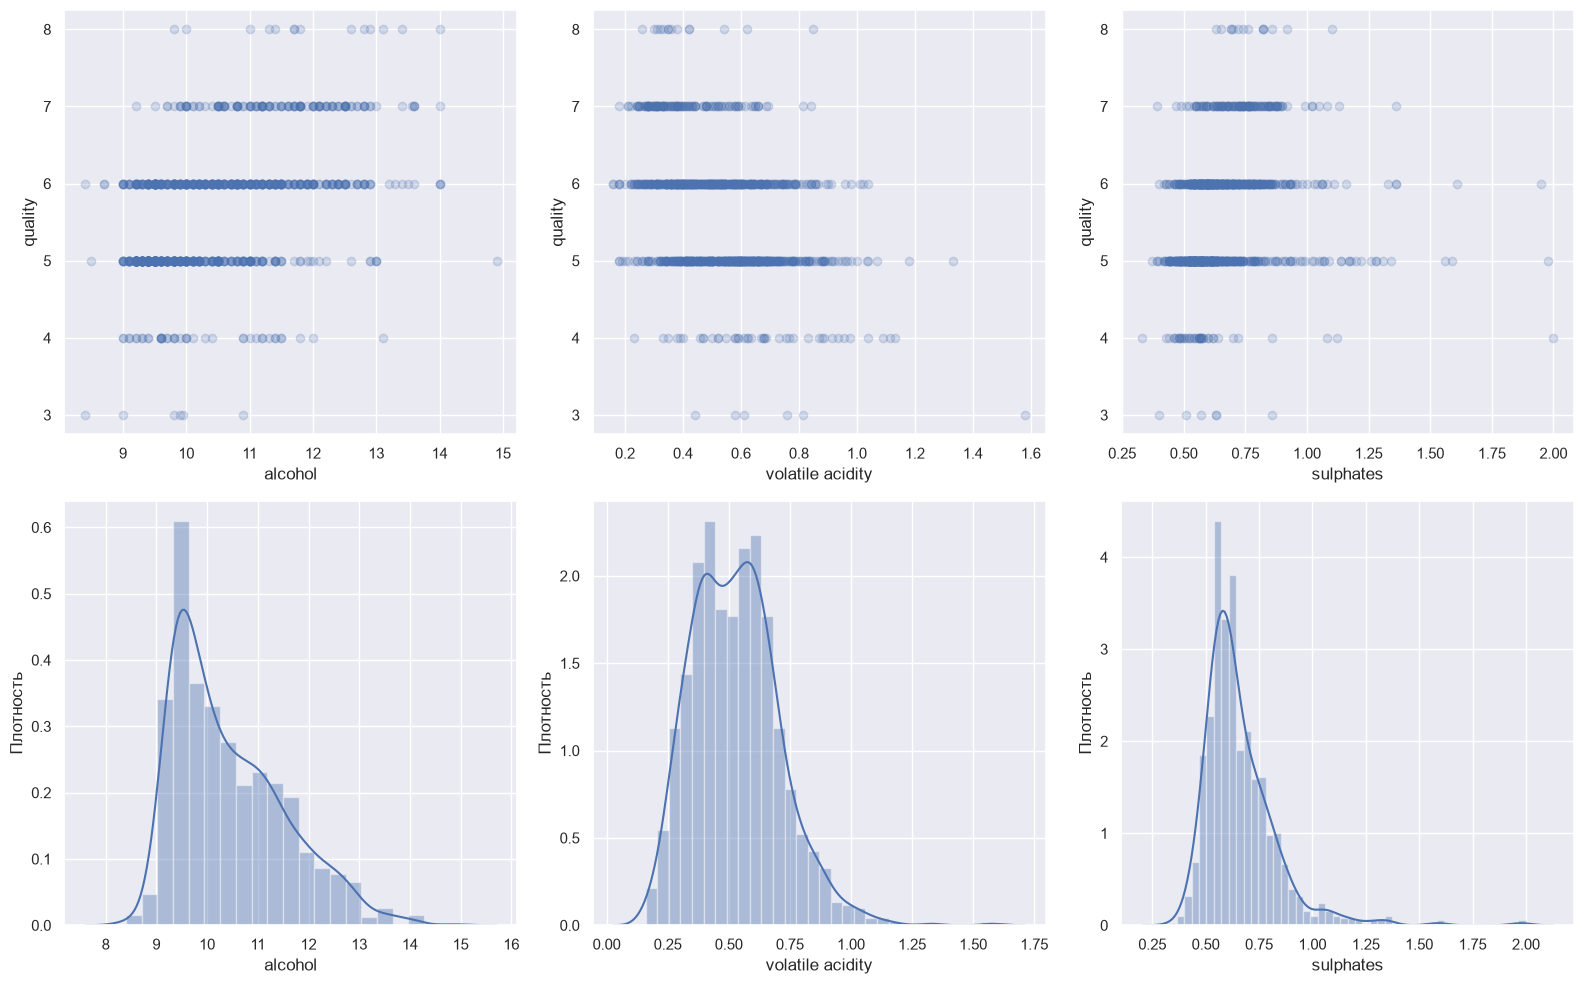

In [9]:
fig, axs = plt.subplots(figsize=(16, 10), nrows=2, ncols=3)
for i, feature in enumerate(["alcohol", "volatile acidity", "sulphates"]):
    axs[0, i].scatter(X_train[feature], y_train, alpha=0.2)
    axs[0, i].set_xlabel(feature)
    axs[0, i].set_ylabel("quality")

for i, feature in enumerate(["alcohol", "volatile acidity", "sulphates"]):
    sns.distplot(X_train[feature], ax=axs[1, i])
    axs[1, i].set_xlabel(feature)
    axs[1, i].set_ylabel("Плотность")
plt.tight_layout()

По графикам заметна нелинейность: точки около значений 4 и 8 сдвинуты вправо относительно самых плотных областей в районе, где quality равна 5-7. При volatile acidity > 0.8, quality в большинстве случаев принимает значение 5, похожая ситуация и у sulphates > 1.0. В alcohol и sulphates наблюдается слабая прямая зависимость quality от этих признаков, однако у sulphates график сжат к меньшим значениям, для volatile acidity наблюдается обратная зависимость.

Так как линейность почти отсутствует, то LinearRegression, вероятно, окажется наименее эффективной для данного датасета.

Построим тепловую матрицу корреляции между всеми признаками для отслеживания мультиколлинеарности.

Text(0.5, 1.0, 'Correlation matrix')

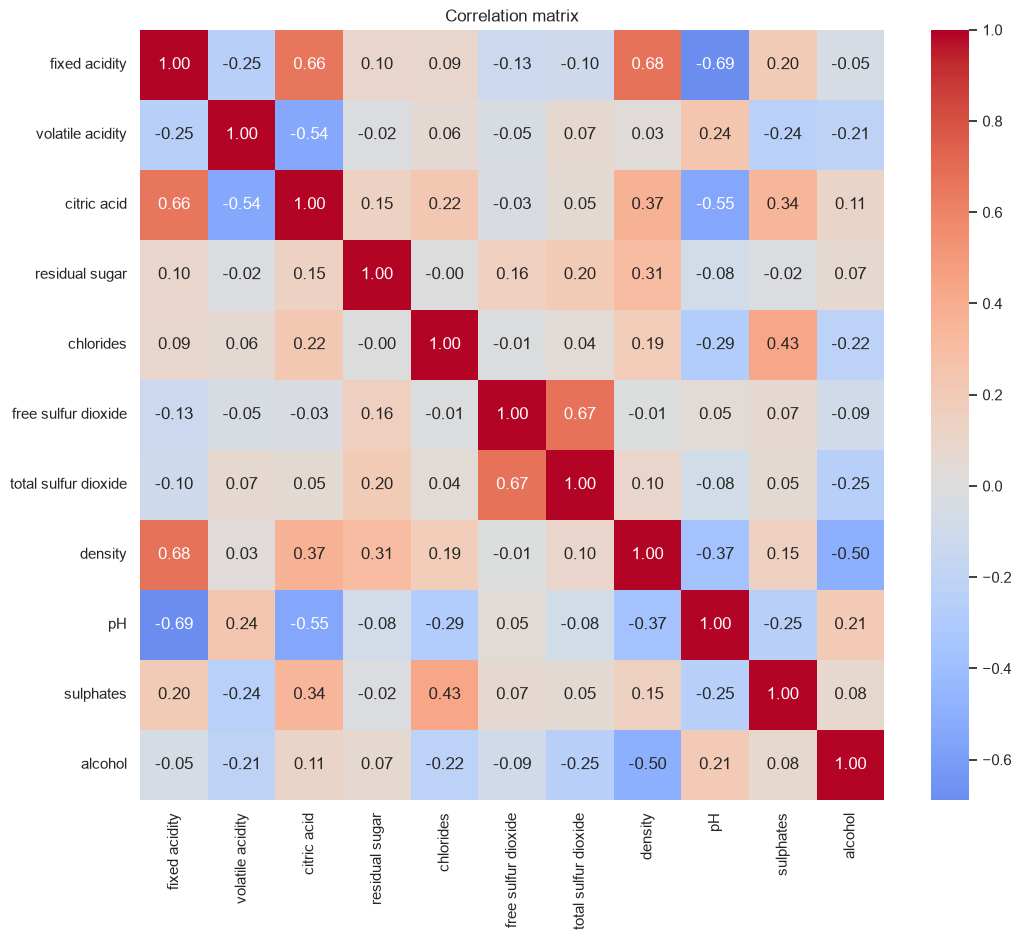

In [10]:
plt.figure(figsize=(12, 10))
sns.heatmap(X_train.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")

Видим, что группа {fixed acidity / citric acid / pH / density} мультиколлинеарна: |corr| > 0.5 в большинстве пар. Это может помешать обучению LinearRegression, т.к. коэффициенты регрессии могут стать нестабильными, хотя итоговый результат может оказаться приемлемым по оценке. Для всех моделей мультиколлинеарность затруднит интерпретацию их коэффициентов. 

Обучим DummyRegressor в качестве baseline.

In [11]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import root_mean_squared_error
from sklearn.metrics import mean_absolute_error

baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)

pred_base = baseline.predict(X_test)
print("Baseline RMSE:", root_mean_squared_error(y_test, pred_base))
print("Baseline MAE:", mean_absolute_error(y_test, pred_base))

Baseline RMSE: 0.8442825185874644
Baseline MAE: 0.7048778342983928


Обучим модель линейной регрессии и посмотрим на получившиеся веса признаков, а также на величины коэффициентов. 

Test RMSE = 0.6565127607976062
Test MAE = 0.5041409053480702


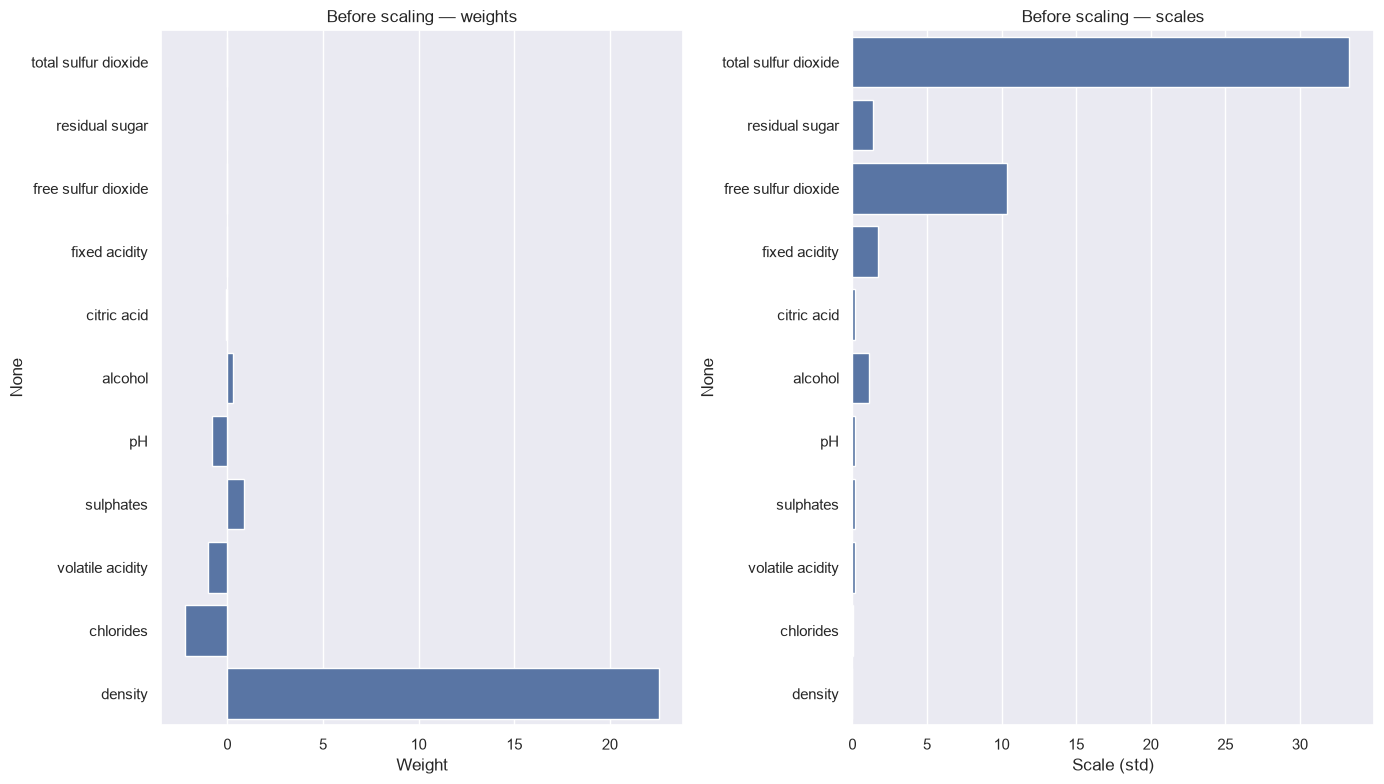

In [12]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

lr_raw = LinearRegression().fit(X_train, y_train)
coef_raw = pd.Series(lr_raw.coef_, index=X_train.columns)
scale_raw = X_train.std()

def show_weights_and_scales(weights, scales, title):
    order = weights.abs().sort_values().index
    w = weights[order]
    s = scales[order]

    fig, axs = plt.subplots(figsize=(14, 8), ncols=2)
    sns.barplot(x=w.values, y=w.index, ax=axs[0])
    axs[0].set_xlabel("Weight")
    axs[0].set_title(f"{title} — weights")

    sns.barplot(x=s.values, y=s.index, ax=axs[1])
    axs[1].set_xlabel("Scale (std)")
    axs[1].set_title(f"{title} — scales")

    plt.tight_layout()
    plt.show()

y_pred = lr_raw.predict(X_test)

print("Test RMSE =", root_mean_squared_error(y_test, y_pred))
print("Test MAE =", mean_absolute_error(y_test, y_pred))

show_weights_and_scales(coef_raw, scale_raw, "Before scaling")

Коэффициенты без масштабирования несопоставимы между признаками: у density вес > 20, у total sulfur dioxide ~ 0 - это следствие разных масштабов, а не важности. Поэтому в Pipeline следует добавить StandardScaler, который делает коэффициенты сравнимыми.

In [13]:
from sklearn.pipeline import Pipeline

linear_regression_pipeline = Pipeline([
    ('scaling', StandardScaler()),
    ('regression', LinearRegression())
])

model = linear_regression_pipeline.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_train_pred = model.predict(X_train)

print("Train RMSE =", root_mean_squared_error(y_train, y_train_pred))
print("Test RMSE =", root_mean_squared_error(y_test, y_pred))
print("Test MAE =", mean_absolute_error(y_test, y_pred))


Train RMSE = 0.6585388890409953
Test RMSE = 0.656512760797608
Test MAE = 0.5041409053480713


Получен приемлимый результат по метрике RMSE < 0.70.

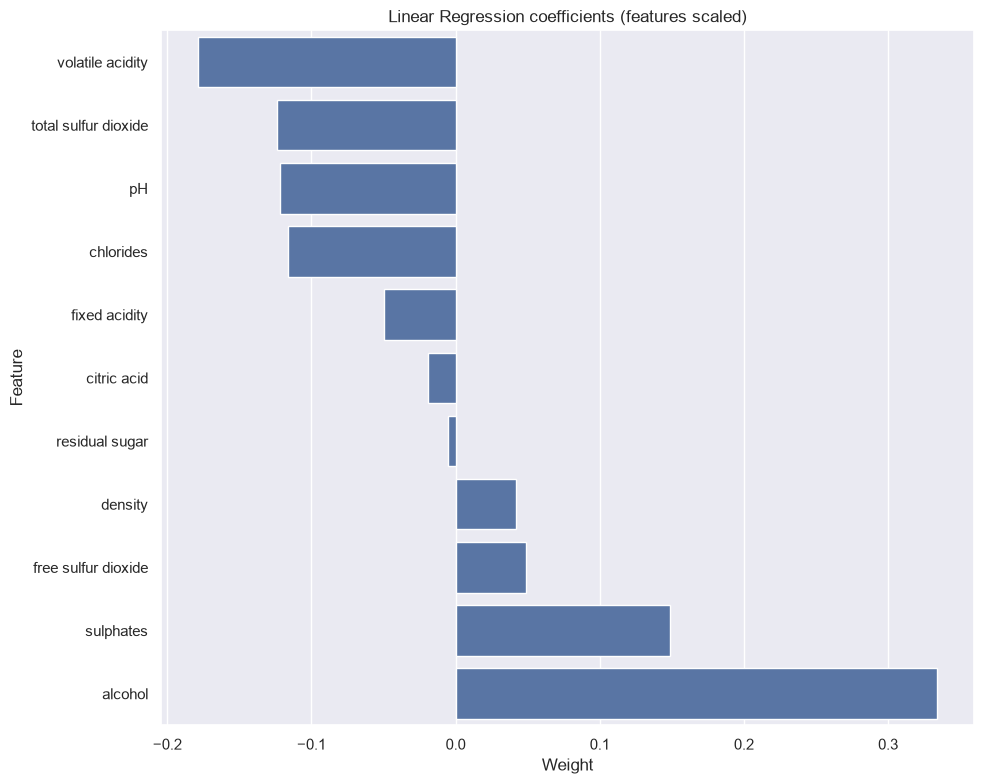

In [14]:
coef = pd.Series(model.named_steps["regression"].coef_, index=X_train.columns)
coef_sorted = coef.sort_values()
plt.figure(figsize=(10, 8))
sns.barplot(x=coef_sorted.values, y=coef_sorted.index)
plt.xlabel("Weight")
plt.ylabel("Feature")
plt.title("Linear Regression coefficients (features scaled)")
plt.tight_layout()

Коэффициенты всё равно не совсем совпадают с корреляциями: коэффициент - это частный эффект при фиксированных остальных, корреляция - попарный. Например, citric acid коррелирует с quality (>0.20), но его вес близок к нулю из-за связи с fixed acidity и pH. Ни коэффициенты, ни feature importance не доказывают причинность: они описывают использование признаков моделью, а не их влияние на цель.

Теперь обучим RandomForest. Для RandomForest и GradientBoosting (далее) масштабирование можно не выполнять, т.к. данные модели не чувствительны к разницам величин между признаками.

In [15]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(random_state=42)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
y_train_pred_rf = rf.predict(X_train)

print("RF Train RMSE =", root_mean_squared_error(y_train, y_train_pred_rf))
print("RF Test RMSE  =", root_mean_squared_error(y_test, y_pred_rf))
print("RF Test MAE   =", mean_absolute_error(y_test, y_pred_rf))



RF Train RMSE = 0.2420908996221312
RF Test RMSE  = 0.6193438178474718
RF Test MAE   = 0.4681617647058824


Результат по метрике RMSE для Test получен приемлемый и немного лучший чем у модели LinearRegression, т.к. корреляции признаков и цели не совсем линейны. Однако заметим, что разрыв между RMSE на Train и RMSE на Test > 0.37, что свидетельствует о переобучении модели.

In [17]:
from sklearn.ensemble import GradientBoostingRegressor

gb = GradientBoostingRegressor(random_state=42)
gb.fit(X_train, y_train)

y_pred_gb = gb.predict(X_test)
y_train_pred_gb = gb.predict(X_train)

print("GB Train RMSE =", root_mean_squared_error(y_train, y_train_pred_gb))
print("GB Test RMSE  =", root_mean_squared_error(y_test, y_pred_gb))
print("GB Test MAE   =", mean_absolute_error(y_test, y_pred_gb))

GB Train RMSE = 0.49425878906747106
GB Test RMSE  = 0.6187955881529541
GB Test MAE   = 0.47848403416127083


Аналогично для GradientBoosting: результат удовлетворительный, однако есть разрыв у RMSE по Train и Test в примерно 0.124.

Хотя значение RMSE выполняет требования лабораторной работы, для чистоты эксперимента попробуем устранить переобучение на Train при помощи Grid Search.

In [22]:
from sklearn.model_selection import GridSearchCV

rf_param_grid = {
    "max_depth": [5, 10, 15, None],
    "min_samples_leaf": [1, 2, 4],
    "n_estimators": [100, 300],
}


rf_search = GridSearchCV(
    RandomForestRegressor(random_state=42),
    rf_param_grid,
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1,
)
rf_search.fit(X_train, y_train)


print("RF best params:", rf_search.best_params_)

RF best params: {'max_depth': None, 'min_samples_leaf': 4, 'n_estimators': 300}


Для RandomForest были выбраны такие параметры как:
1. max_depth - максимальная глубина каждого дерева. Без ограничения (None) дерево построит максиально подробные правила и запомнит Train.
2. min_samples_leaf - устанавливает минимальное количество объектов в листе. Стандартное значение 1 - буквально запоминание, при больших значениях дерево будет обобщать и реально предсказывать.
3. n_estimators - количество деревьев "в лесу". Почти не влияет на переоучение, но обеспечивает стабильность результата.

In [18]:
gb_param_grid = {
    "learning_rate": [0.05, 0.1],
    "n_estimators": [100, 200, 300],
}

gb_search = GridSearchCV(
    GradientBoostingRegressor(random_state=42),
    gb_param_grid,
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1,
)
gb_search.fit(X_train, y_train)

print("GB best params:", gb_search.best_params_)

GB best params: {'learning_rate': 0.05, 'n_estimators': 100}


Для GradientBoosting были выбраны такие параметры как:
1. learning_rate - влияние каждого дерева на предсказание. Больше значение - быстрее учится, но может вызвать переобучение, маленькое значение - дольше учится, требует больше деревьев. Работает в паре с n_estimators.
2. n_estimators - количество последовательных деревьев "в лесу". Влияет на переобучение: больше деревьев - модель больше подгоняется под train и запоминает его.

In [23]:
rf_best = rf_search.best_estimator_
gb_best = gb_search.best_estimator_

rows = []
for name, model in [("RF tuned", rf_best), ("GB tuned", gb_best)]:
    tr = root_mean_squared_error(y_train, model.predict(X_train))
    te = root_mean_squared_error(y_test,  model.predict(X_test))
    ma = mean_absolute_error(y_test, model.predict(X_test))
    rows.append({"Модель": name, "Train RMSE": tr, "Test RMSE": te,
                 "Test MAE": ma, "Разрыв": te - tr})

pd.DataFrame(rows)

,Модель,Train RMSE,Test RMSE,Test MAE,Разрыв
0,RF tuned,0.399627,0.615707,0.464243,0.216080
1,GB tuned,0.541560,0.620295,0.479857,0.078736


Получилось сократить разрыв: GradientBoostingRegressor вовсе перестал переобучаться, RandomForestRegressor сохраняет достаточно большой разрыв между Train и Test, однако он стал более чем в 1.5 раза меньше (0.37 против 0.21). Разрыв сохраняется из-за бедного разнообразия значения целевой переменной.

In [24]:
baseline = DummyRegressor(strategy="mean").fit(X_train, y_train)
pred = baseline.predict(X_test)

linreg = Pipeline([
    ("scaling", StandardScaler()),
    ("regression", LinearRegression()),
]).fit(X_train, y_train)

models = {
    "Baseline":           baseline,
    "Linear Regression":  linreg,
    "Random Forest":      rf_search.best_estimator_,
    "Gradient Boosting":  gb_search.best_estimator_,
}

rows = []
for name, model in models.items():
    pred = model.predict(X_test)
    rows.append({
        "Модель": name,
        "RMSE": round(root_mean_squared_error(y_test, pred), 4),
        "MAE":  round(mean_absolute_error(y_test, pred), 4),
    })

pd.DataFrame(rows)

,Модель,RMSE,MAE
0,Baseline,0.8443,0.7049
1,Linear Regression,0.6565,0.5041
2,Random Forest,0.6157,0.4642
3,Gradient Boosting,0.6203,0.4799


Все три обученные модели превзошли Baseline и прошли порог RMSE < 0.70. Лучшей по обоим метрикам RMSE и MAE оказалась модель RandomForestRegressor, однако GradientBoostingRegressor отстает лишь на сотые доли, что больше походит на шум. LinearRegression немного, но уступает обоим деревьям, что ожидаемо, т.к. связи параметров датасета с целевой quality частично нелинейные и их плохо ловит линейная модель. На небольшом датасете с дискретной целевой переменной преимущество одного алгоритма над другим минимально.

Проанализируем feature importance для RandomForest и GradientBoosting.

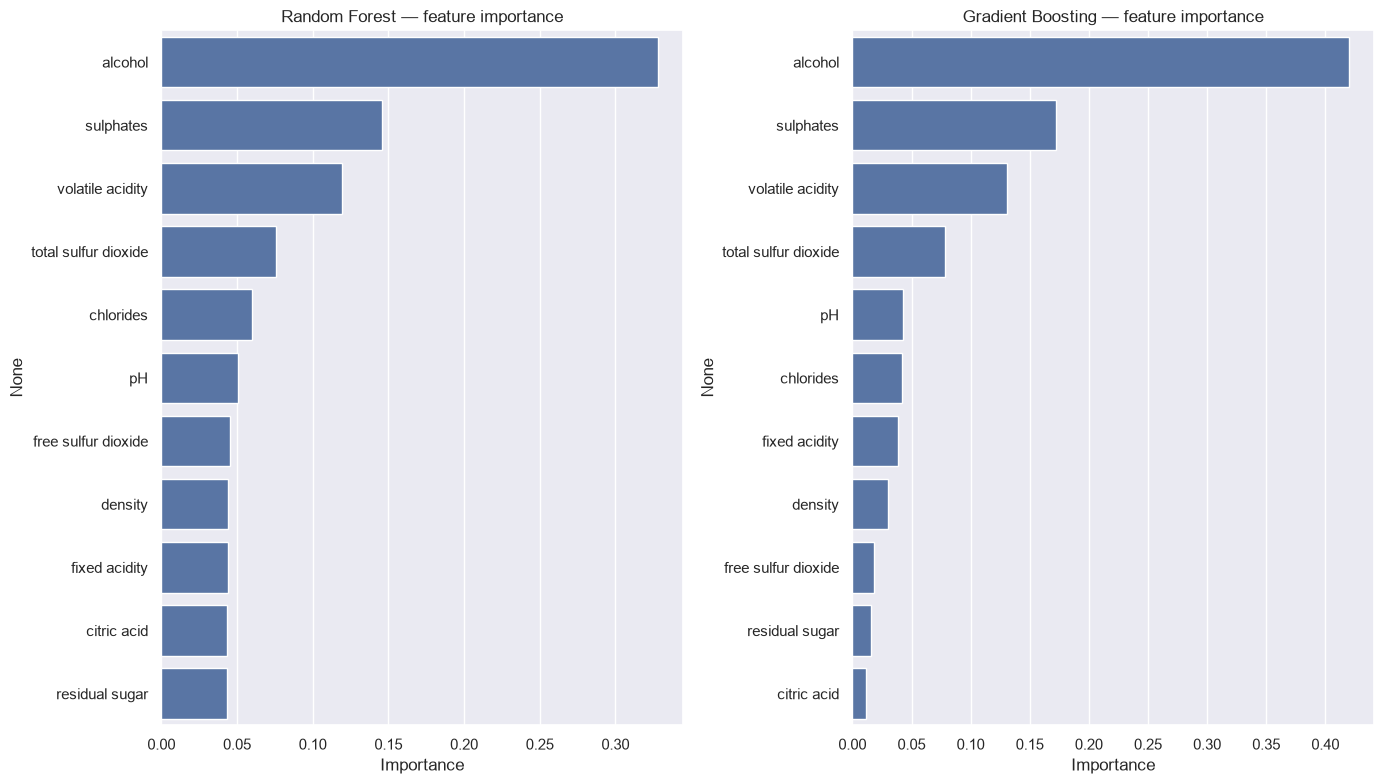

RF top-5: ['alcohol', 'sulphates', 'volatile acidity', 'total sulfur dioxide', 'chlorides']
GB top-5: ['alcohol', 'sulphates', 'volatile acidity', 'total sulfur dioxide', 'pH']


In [58]:
rf_imp = pd.Series(rf_best.feature_importances_, index=X_train.columns).sort_values(ascending=False)
gb_imp = pd.Series(gb_best.feature_importances_, index=X_train.columns).sort_values(ascending=False)

fig, axs = plt.subplots(figsize=(14, 8), ncols=2)

sns.barplot(x=rf_imp.values, y=rf_imp.index, ax=axs[0])
axs[0].set_title("Random Forest — feature importance")
axs[0].set_xlabel("Importance")

sns.barplot(x=gb_imp.values, y=gb_imp.index, ax=axs[1])
axs[1].set_title("Gradient Boosting — feature importance")
axs[1].set_xlabel("Importance")

plt.tight_layout()
plt.show()

print("RF top-5:", list(rf_imp.head(5).index))
print("GB top-5:", list(gb_imp.head(5).index))

Топ-3 признака совпали с исследуемыми на корреляцию с target quality, однако информативность отдельных признаков группы {fixed acidity / citric acid / pH / density} отличились от значений при иследовании датасета, причиной этому является их мультиколлинеарность, из-за этого произошло "перераспределение" importance между элементами группы. Вместе они все равно являются сильными признаками для моделей. Совпадение топ-4 по важности признаков между двумя моделями свидетельствует об устойчивости выделенных признаков.

На основании feature importance нельзя утверждать, что изменение признака является причиной изменения quality. Feature importance показывает, насколько модель использует признак для предсказания. Причинно-следственная связь требует эксперимента, например контролируемое изменение признака при фиксированных остальных. Так, высокая важность alcohol не доказывает, что если в вине искусственно поднять спирт, качество вырастет - это лишь значит, что модель опирается на alcohol при построении прогноза.

Проведем анализ ошибок лучшей модели, а именно RandomForestRegressor.

Text(0.5, 0, 'error')

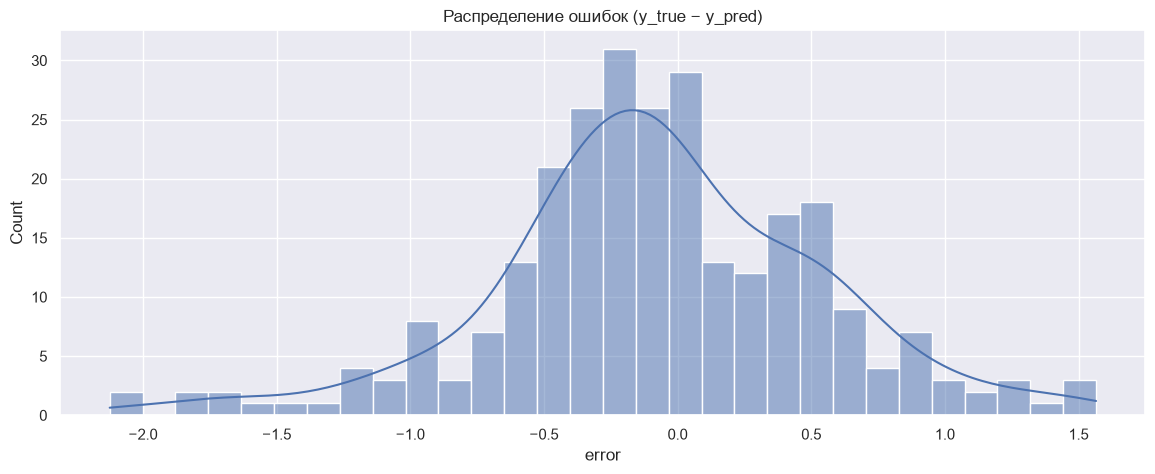

In [59]:
best_model = rf_best
y_pred_best = best_model.predict(X_test)
errors = y_test - y_pred_best
abs_errors = np.abs(errors)

fig, axs = plt.subplots(figsize=(14, 5), ncols=1)
sns.histplot(errors, bins=30, kde=True, ax=axs)
axs.set_title("Распределение ошибок (y_true − y_pred)")
axs.set_xlabel("error")



In [60]:
err_df = pd.DataFrame({
    "y_true": y_test.values,
    "y_pred": np.round(y_pred_best, 2),
    "error": errors.values,
    "abs_error": abs_errors.values,
}, index=y_test.index)

top_errors = err_df.sort_values("abs_error", ascending=False).head(10)
print(top_errors)

      y_true  y_pred     error  abs_error
1245       3    5.12 -2.124681   2.124681
1253       3    5.05 -2.051950   2.051950
771        3    4.79 -1.787280   1.787280
1206       4    5.78 -1.775578   1.775578
1258       4    5.71 -1.710819   1.710819
597        3    4.66 -1.657089   1.657089
799        4    5.59 -1.587905   1.587905
554        7    5.43  1.565691   1.565691
715        8    6.48  1.520429   1.520429
560        4    5.47 -1.473139   1.473139


Из топа объектов с самыми большимы ошибками видно, что модель ошиается чаще всего на редких данных: строки со значениями quality 3, 4, 7, 8. Модели не хватило информации датасета, чтобы научиться достаточно точно их распознавать. 

In [61]:
err_by_quality = err_df.groupby("y_true").agg(
    count=("abs_error", "size"),
    mean_abs_error=("abs_error", "mean"),
    max_abs_error=("abs_error", "max"),
    mean_pred=("y_pred", "mean"),
).round(3)
print(err_by_quality)

        count  mean_abs_error  max_abs_error  mean_pred
y_true                                                 
3           4           1.905          2.125      4.905
4          11           1.347          1.776      5.347
5         120           0.346          1.133      5.334
6         103           0.374          1.303      5.833
7          31           0.628          1.566      6.375
8           3           1.425          1.520      6.577


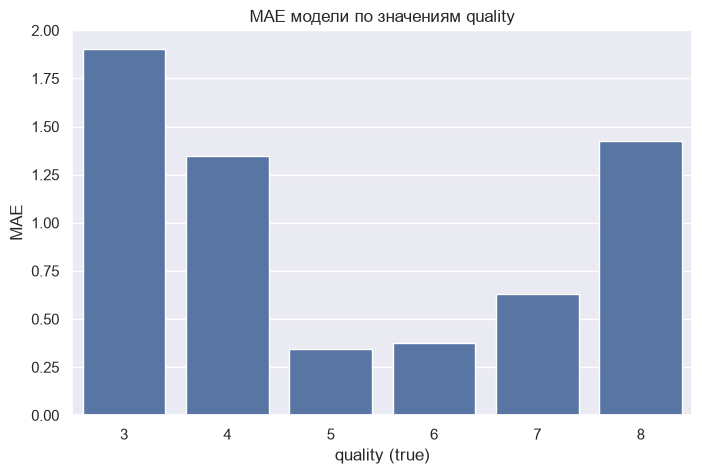

In [62]:
plt.figure(figsize=(8, 5))
sns.barplot(x=err_by_quality.index, y=err_by_quality["mean_abs_error"])
plt.xlabel("quality (true)")
plt.ylabel("MAE")
plt.title("MAE модели по значениям quality")
plt.show()

На редких quality (3, 8) MAE существенно выше, чем на массовых (5, 6). Это ожидаемо по трём причинам:
1. В train мало примеров с quality = 3 и quality = 8, модель не выучивает их профиль.
2. Деревья в листьях усредняют - редкие значения "размываются" ближе к среднему.
3. quality - дискретная переменная, а модель предсказывает непрерывные значения. например, при истинном значении 3 модель даёт 3.5-4, ошибка >= 0.5, а при истинном 8 - 7.0-7.5, ошибка >= 0.5. Это структурный предел алгоритма.